# 08 - Decision attacks, corrected: one image per pair, both directions, 6,000 pairs

**This notebook supersedes Part A of `03-attacks.ipynb` and Part 0 of `04`.**
It addresses the fourth point of the supervisor review:

> * In the adversarial attack, you seem to attack the same image, however you should
>   attack of course only one image of the pair (and not the same image). This part is
>   confusing especially, as your Adversarial genuine image has a higher similarity
>   (while the goal should be to decrease similarity) same is also true for your Imposter
>   Pair. In the imposter pair, the similarity should increase not decrease.

## What was actually wrong

Two separate problems produced that symptom, and only one of them was ever fixed.

**Problem 1 - the sign, fixed in notebook 04.** Notebook 03 updated
`img + alpha * grad.sign()` (gradient *ascent*) while its loss functions already carried
the attack sign. Every attack therefore drove the similarity confidently in the wrong
direction, which is why all four warm-ups reported `flip_rate = 0.00` despite a large
mean `|delta sim|`. Notebook 04 rewrote the step as descent on a loss to minimise and
got `flip_rate = 1.00` on genuine pairs.

**Problem 2 - the imposter direction, never fixed until now.** Notebook 04 restricted
itself to genuine pairs and **dropped imposter pairs entirely**. So the direction flagged
in the review - "in the imposter pair, the similarity should increase not decrease" - has
never actually been demonstrated in this project. That is what this notebook closes.

## The two directions, stated explicitly

| Pair type | Attack | Goal | Correct sign of `delta sim` | Success |
|---|---|---|---|---|
| **genuine** | obfuscation | make the system think they are *different* people | **negative** | score falls below the threshold |
| **imposter** | impersonation | make the system think they are the *same* person | **positive** | score rises above the threshold |

The two headline numbers to check in the output are the mean `delta sim` per direction.
If genuine is not negative and imposter not positive, the sign is inverted again.

## "Only one image of the pair"

Every pair is split into a **probe** - the single image the attacker is allowed to
modify - and a **reference**, which is passed through the model untouched. The split is
made once in the config (`probe_reference()`), asserted to name two different files, and
carried identically through notebooks 08 and 09. With `PROBE_SIDE="random"` the probe is
chosen by a seeded per-pair coin flip, so the attacked image is not systematically image
0 of every pair, and the run stays reproducible. Every figure and every CSV row names
both source files.

## A units fix worth noting

Notebooks 03-05 set `EPSILON = 0.03` and described it as "8/255 per pixel". That is
wrong. Images are normalised to `[-1, 1]` by `x/127.5 - 1`, so 0.03 in normalised space
is `0.03 * 127.5 = 3.8` grey levels, not 8. This notebook specifies the budget in **grey
levels out of 255** and converts, so the perturbation size means what it says.

## CONFIG - edit only this cell

In [1]:
import torch

# =================================================================
# PATHS - update to match your Kaggle dataset / model slugs
# =================================================================
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# =================================================================
# DATASET LAYOUT  -  the fix for feedback point 1
# =================================================================
# The image directory holds 12,000 files (0.jpg .. 11999.jpg), i.e. 6,000
# pairs, NOT the 900 pairs used in notebooks 01-05.  Consecutive images form
# a pair (0,1), (2,3), ...  The pairs follow the standard LFW view-2 layout:
# 10 folds x 600 pairs, and each fold is 300 genuine pairs followed by 300
# imposter pairs.  Notebook 06 verifies this empirically before use.
N_IMAGES         = 12000
N_PAIRS          = N_IMAGES // 2      # 6000
PAIRS_PER_FOLD   = 600
GENUINE_PER_FOLD = 300
N_FOLDS          = N_PAIRS // PAIRS_PER_FOLD   # 10

# =================================================================
# PROBE / REFERENCE  -  the fix for feedback point 4
# =================================================================
# An attack may modify exactly ONE image of a pair: the "probe".  The other
# image, the "reference", is never touched.  PROBE_SIDE="random" picks the
# side with a seeded per-pair coin flip, so the attacked image is not
# systematically image 0 of every pair while the run stays reproducible.
PROBE_SIDE = "random"        # 0 | 1 | "random"
PROBE_SEED = 20260728

# =================================================================
# MODEL
# =================================================================
NUM_FEATURES = 512
IMG_SIZE     = 112

# =================================================================
# THIS NOTEBOOK
# =================================================================
MAX_PAIRS    = None     # None = all 6,000 pairs
ATTACK_BATCH = 64

# Perturbation budget in GREY LEVELS out of 255.  Images live in [-1,1], so
# the budget used by the attack is EPS_255 / 127.5.
#   1/255 -> 0.0078   2/255 -> 0.0157   4/255 -> 0.0314   8/255 -> 0.0627
# (Notebooks 03-05 used 0.03 in [-1,1] space, i.e. 3.8/255, while describing
#  it as 8/255.)
EPSILONS_255 = [1.0, 2.0, 4.0, 8.0]
MAIN_EPS_255 = 4.0      # the budget used for the headline table and figures

STEPS_IFGSM = 20        # I-FGSM iterations
ALPHA_FRAC  = 0.25      # step size as a fraction of epsilon

CHECKPOINT_EVERY = 1000

VIZ_GENUINE_PAIR  = 0
VIZ_IMPOSTER_PAIR = 300

# =================================================================
# RUNTIME
# =================================================================
USE_AMP        = True     # fp16 autocast for EVALUATION forward passes only
                          # (never inside an attack loop - see notebook 08/09)
EMBED_BATCH    = 128      # batch size for plain embedding extraction
PRELOAD_IMAGES = True     # cache all 12,000 images in RAM (~450 MB)
N_GPUS         = None     # None = use every visible GPU.  Kaggle's "GPU T4 x2"
                          # exposes two; set to 1 to force single-GPU.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary device : {DEVICE}")
for _i in range(torch.cuda.device_count()):
    _p = torch.cuda.get_device_properties(_i)
    print(f"  cuda:{_i} : {_p.name}  {_p.total_memory / 1e9:.1f} GB")

Primary device : cuda
  cuda:0 : Tesla T4  15.6 GB
  cuda:1 : Tesla T4  15.6 GB


## Imports

In [2]:
import os
import json
import math
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from contextlib import nullcontext
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

## Backbone

In [3]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data, threshold and plotting utilities

In [4]:
# ---------------------------------------------------------------- images ---
def preprocess(img_rgb):
    """(H,W,3) uint8 RGB -> (3,H,W) float32 tensor in [-1, 1]."""
    x = ((img_rgb.astype(np.float32) / 255.0) - 0.5) / 0.5
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))


IMAGE_CACHE = None

def _read_image(img_idx):
    path = os.path.join(IMAGES_DIR, f"{img_idx}.jpg")
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preload_images(n=N_IMAGES):
    """Hold every image in RAM so the long loops never re-decode a JPEG."""
    global IMAGE_CACHE
    cache = np.zeros((n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i in tqdm(range(n), desc="Caching images", leave=False):
        cache[i] = _read_image(i)
    IMAGE_CACHE = cache
    print(f"Cached {n:,} images ({cache.nbytes / 1e6:.0f} MB)")


def image_rgb(img_idx):
    return IMAGE_CACHE[img_idx] if IMAGE_CACHE is not None else _read_image(img_idx)


def image_tensor(img_idx):
    return preprocess(image_rgb(img_idx))


def tensor_to_uint8(t):
    """(3,H,W) or (1,3,H,W) float tensor in [-1,1] -> (H,W,3) uint8."""
    x = t.detach().float().cpu().numpy()
    if x.ndim == 4:
        x = x[0]
    x = x.transpose(1, 2, 0)
    return np.clip((x * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)


# ------------------------------------------------------- pair bookkeeping ---
def _build_probe_sides():
    if PROBE_SIDE in (0, 1):
        return np.full(N_PAIRS, int(PROBE_SIDE), dtype=np.int64)
    if PROBE_SIDE != "random":
        raise ValueError(f"PROBE_SIDE must be 0, 1 or 'random', got {PROBE_SIDE!r}")
    return np.random.RandomState(PROBE_SEED).randint(0, 2, size=N_PAIRS)

PROBE_SIDES = _build_probe_sides()


def probe_reference(pair_idx):
    """(probe_img_idx, reference_img_idx) - always two DIFFERENT image files.

    The probe is the ONLY image any attack in this project is allowed to
    modify; the reference is passed through the model untouched.
    """
    i0, i1 = 2 * int(pair_idx), 2 * int(pair_idx) + 1
    probe, ref = (i0, i1) if PROBE_SIDES[pair_idx] == 0 else (i1, i0)
    assert probe != ref, "probe and reference must be two different images"
    return probe, ref


def is_genuine(pair_idx):
    """LFW view-2: every fold is 300 genuine pairs then 300 imposter pairs."""
    return (np.asarray(pair_idx) % PAIRS_PER_FOLD) < GENUINE_PER_FOLD


def fold_of(pair_idx):
    return np.asarray(pair_idx) // PAIRS_PER_FOLD


PAIR_IDX   = np.arange(N_PAIRS)
IS_GENUINE = is_genuine(PAIR_IDX)
FOLD       = fold_of(PAIR_IDX)
PROBE_IMG  = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX, 2 * PAIR_IDX + 1)
REF_IMG    = np.where(PROBE_SIDES == 0, 2 * PAIR_IDX + 1, 2 * PAIR_IDX)


def load_pair_batch(pair_indices, device=None):
    """-> (probes, references), each (B,3,112,112) on DEVICE."""
    device = device or DEVICE
    probes = torch.stack([image_tensor(int(PROBE_IMG[i])) for i in pair_indices]).to(device)
    refs   = torch.stack([image_tensor(int(REF_IMG[i]))   for i in pair_indices]).to(device)
    return probes, refs


# ----------------------------------------------------------------- model ---
def amp_ctx(device=None):
    dev = DEVICE if device is None else device
    if USE_AMP and dev.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def load_model_on(dev):
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    m = m.to(dev).eval()
    # We only ever differentiate w.r.t. the INPUT image, never the weights.
    # Freezing the parameters keeps the second-order graphs in notebook 09
    # from also tracking weight gradients.
    for p in m.parameters():
        p.requires_grad_(False)
    return m


def load_model():
    return load_model_on(DEVICE)


@torch.no_grad()
def embed_batch(x):
    """(B,3,H,W) -> (B,D) L2-normalised embeddings (float32)."""
    with amp_ctx(x.device):
        e = current_model()(x)
    return F.normalize(e.float(), dim=1)


@torch.no_grad()
def embed_images(img_indices, batch=None, desc="Embedding"):
    batch = batch or EMBED_BATCH
    img_indices = np.asarray(img_indices)
    out = np.zeros((len(img_indices), NUM_FEATURES), dtype=np.float32)
    for s in tqdm(range(0, len(img_indices), batch), desc=desc, leave=False):
        chunk = img_indices[s:s + batch]
        x = torch.stack([image_tensor(int(i)) for i in chunk]).to(DEVICE)
        out[s:s + len(chunk)] = embed_batch(x).cpu().numpy()
    return out


def compute_all_scores():
    """Embed all 12,000 images and return (embeddings, 6,000 pair scores)."""
    emb = embed_images(np.arange(N_IMAGES), desc="Embedding 12,000 images")
    scores = (emb[0::2] * emb[1::2]).sum(1)   # cosine similarity per pair
    return emb, scores

# =========================================================================
# Multi-GPU execution
# =========================================================================
# Kaggle's "GPU T4 x2" accelerator gives two devices; a single-threaded loop
# uses one and leaves the other idle.  The work in these notebooks is
# embarrassingly parallel across pairs - every pair's saliency map and
# insertion/deletion curve is independent of every other - so it splits
# cleanly: give each GPU its own replica of the model and hand each a
# different chunk of pairs.
#
# Threads, not processes.  CUDA kernel launches release the GIL, so two
# threads driving two devices genuinely overlap, and they share the 452 MB
# image cache rather than duplicating it per process.  Each thread keeps its
# replica in thread-local storage; `current_model()` is what every forward
# pass in this notebook actually calls.
#
# Autocast, no_grad and the autograd graph are all thread-local in PyTorch,
# so the saliency and attack code needs no locking.
import threading
from concurrent.futures import ThreadPoolExecutor

_TLS = threading.local()


def available_devices(limit=None):
    n = torch.cuda.device_count()
    if n == 0:
        return [torch.device("cpu")]
    return [torch.device(f"cuda:{i}") for i in range(n if limit is None else min(n, limit))]


DEVICES = available_devices(N_GPUS)


def current_model():
    """The model replica belonging to the calling thread."""
    m = getattr(_TLS, "model", None)
    return MODELS[DEVICES[0]] if m is None else m


def parallel_chunks(chunk_list, worker, desc=""):
    """Run worker(i, chunk, device) over chunk_list, one thread per GPU.

    Yields results in submission order, so downstream code can rely on the
    ordering while the GPUs run out of order underneath.
    """
    if len(DEVICES) == 1:
        _TLS.model = MODELS[DEVICES[0]]
        for i, ch in enumerate(tqdm(chunk_list, desc=desc)):
            yield worker(i, ch, DEVICES[0])
        return

    def run(i, ch):
        dev = DEVICES[i % len(DEVICES)]
        _TLS.model = MODELS[dev]
        with torch.cuda.device(dev):
            return worker(i, ch, dev)

    with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
        futures = [ex.submit(run, i, ch) for i, ch in enumerate(chunk_list)]
        for f in tqdm(futures, desc=f"{desc} [{len(DEVICES)} GPUs]"):
            yield f.result()


def chunk_offsets(chunk_list):
    """Start index of each chunk in the flattened pair ordering."""
    return np.concatenate([[0], np.cumsum([len(c) for c in chunk_list])]).astype(int)

# ------------------------------------------------- FMR / FNMR / EER tools ---
# FMR  (False Match Rate)     = fraction of IMPOSTER pairs scoring >= threshold
# FNMR (False Non-Match Rate) = fraction of GENUINE  pairs scoring <  threshold
# Both are computed exactly by binary search on the sorted score arrays - no
# histogram binning, no interpolation.

def fmr_at(imposter_sorted, t):
    n = len(imposter_sorted)
    return 1.0 - np.searchsorted(imposter_sorted, t, side="left") / n


def fnmr_at(genuine_sorted, t):
    n = len(genuine_sorted)
    return np.searchsorted(genuine_sorted, t, side="left") / n


def candidate_thresholds(genuine_sorted, imposter_sorted):
    """Every score, and every score nudged up by one ulp: the complete set of
    operating points at which FMR/FNMR can change."""
    c = np.unique(np.concatenate([genuine_sorted, imposter_sorted]))
    c = np.unique(np.concatenate([c, np.nextafter(c, np.inf)]))
    return c


def compute_eer(genuine_sorted, imposter_sorted):
    """Exact EER and the threshold that achieves it."""
    c = candidate_thresholds(genuine_sorted, imposter_sorted)
    fmr, fnmr = fmr_at(imposter_sorted, c), fnmr_at(genuine_sorted, c)
    k = int(np.argmin(np.abs(fmr - fnmr)))
    return float(c[k]), float((fmr[k] + fnmr[k]) / 2.0)


def threshold_at_fmr(imposter_sorted, target_fmr):
    """Lowest threshold whose FMR is <= target_fmr."""
    n = len(imposter_sorted)
    k = int(np.floor(target_fmr * n))            # imposters we are allowed to accept
    if k >= n:
        return float(imposter_sorted[0])
    return float(np.nextafter(imposter_sorted[n - 1 - k], np.inf))


def operating_point(scores, genuine_mask, t):
    """(FMR, FNMR, accuracy) of threshold t on a set of scores."""
    g = scores[genuine_mask]
    i = scores[~genuine_mask]
    fmr  = float((i >= t).mean())
    fnmr = float((g <  t).mean())
    acc  = float(((g >= t).sum() + (i < t).sum()) / len(scores))
    return fmr, fnmr, acc

# --------------------------------------------------------------- display ---
def overlay(img_tensor, sal_np, alpha=0.5):
    """Blend a [0,1] saliency map over the image as a JET heatmap."""
    raw = tensor_to_uint8(img_tensor)
    hm = cv2.applyColorMap((np.clip(sal_np, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)
    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
    return np.clip(alpha * hm + (1 - alpha) * raw, 0, 255).astype(np.uint8)


def to01(m):
    m = np.asarray(m, dtype=np.float64)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def save_fig(name, dpi=140):
    path = os.path.join(OUTPUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved", path)

# ------------------------------------------------------------ checkpoints ---
# Kaggle sessions die; long loops should not lose their work when they do.
# Tracks the last saved row count rather than testing `len(rows) % every == 0`,
# which only fires when the batch size happens to divide `every`.
_CKPT_SAVED = {}

def checkpoint_rows(rows, filename, every=None, force=False):
    every = CHECKPOINT_EVERY if every is None else every
    if force or len(rows) - _CKPT_SAVED.get(filename, 0) >= every:
        pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        _CKPT_SAVED[filename] = len(rows)
    return rows

def batches(seq, size):
    """Yield consecutive slices of an index array."""
    seq = np.asarray(seq)
    for s in range(0, len(seq), size):
        yield seq[s:s + size]

## Load model, cache images, recompute the protocol

In [5]:
# One replica per GPU.  `model` stays the primary replica so the plotting and
# single-pair helpers below work unchanged in the main thread; the worker
# threads pick up their own replica via current_model().
MODELS = {d: load_model_on(d) for d in DEVICES}
model = MODELS[DEVICES[0]]
_TLS.model = model
print(f"ElasticFace-Arc loaded on {len(DEVICES)} device(s): "
      f"{', '.join(str(d) for d in DEVICES)}")
print(f"  {sum(p.numel() for p in model.parameters()):,} parameters per replica")

if PRELOAD_IMAGES:
    preload_images()

emb, scores = compute_all_scores()
gen_sorted = np.sort(scores[IS_GENUINE])
imp_sorted = np.sort(scores[~IS_GENUINE])

TAU_EER, EER = compute_eer(gen_sorted, imp_sorted)
THRESHOLDS = {"EER": TAU_EER}
for target in [1e-1, 1e-2, 1e-3]:
    THRESHOLDS[f"FMR<={target:g}"] = threshold_at_fmr(imp_sorted, target)

print(f"EER = {EER:.3%} at threshold {TAU_EER:.4f}")
for k, v in THRESHOLDS.items():
    print(f"  {k:>12} : {v:.4f}")

# Every image belongs to exactly one pair, so 12,000 images == 6,000 pairs and
# nothing is left unused.  Asserted rather than asserted-in-prose because
# "6,000" next to "12,000 images" reads like half the data is being skipped.
_used = np.unique(np.concatenate([PROBE_IMG, REF_IMG]))
assert len(_used) == N_IMAGES, "probe+reference must cover every image exactly once"

print("Environment ready.")
print(f"  images used     : {len(_used):,} / {N_IMAGES:,}  (each image is in exactly one pair)")
print(f"  pairs           : {N_PAIRS:,} = {N_IMAGES:,} images / 2  "
      f"({int(IS_GENUINE.sum()):,} genuine / {int((~IS_GENUINE).sum()):,} imposter) "
      f"in {N_FOLDS} folds")
print(f"  probe selection : PROBE_SIDE={PROBE_SIDE!r}  seed={PROBE_SEED}  "
      f"(1 image attacked per pair, 1 left untouched)")

ElasticFace-Arc loaded on 2 device(s): cuda:0, cuda:1
  65,156,160 parameters per replica


Caching images:   0%|          | 0/12000 [00:00<?, ?it/s]

Cached 12,000 images (452 MB)


Embedding 12,000 images:   0%|          | 0/94 [00:00<?, ?it/s]

EER = 0.300% at threshold 0.2134
           EER : 0.2134
      FMR<=0.1 : 0.0942
     FMR<=0.01 : 0.1684
    FMR<=0.001 : 0.2484
Environment ready.
  images used     : 12,000 / 12,000  (each image is in exactly one pair)
  pairs           : 6,000 = 12,000 images / 2  (3,000 genuine / 3,000 imposter) in 10 folds
  probe selection : PROBE_SIDE='random'  seed=20260728  (1 image attacked per pair, 1 left untouched)


## Verifying the probe / reference split

Before attacking anything, make the split visible. This is the check that the ambiguity
in the review cannot recur: for a random sample of pairs we print the two image files and
assert they are different, and confirm that across the dataset the probe is drawn from
both sides of the pair rather than always being image 0.

In [6]:
print(f"{'pair':>5}  {'label':9}  {'probe':>9}  {'reference':>10}  {'side':>5}")
for p in [0, 1, 2, 300, 301, 3000, 5999]:
    pr, rf = probe_reference(p)
    assert pr != rf
    print(f"{p:5d}  {'genuine' if IS_GENUINE[p] else 'imposter':9}  "
          f"{pr:>5}.jpg  {rf:>6}.jpg  {int(PROBE_SIDES[p]):>5}")

assert (PROBE_IMG != REF_IMG).all(), "some pair has the same image as probe and reference"
frac_side0 = float((PROBE_SIDES == 0).mean())
print(f"\nprobe is image 0 of the pair in {frac_side0:.1%} of pairs, "
      f"image 1 in {1 - frac_side0:.1%}")
print("every pair uses two different image files: OK")

 pair  label          probe   reference   side
    0  genuine        0.jpg       1.jpg      0
    1  genuine        3.jpg       2.jpg      1
    2  genuine        4.jpg       5.jpg      0
  300  imposter     601.jpg     600.jpg      1
  301  imposter     603.jpg     602.jpg      1
 3000  genuine     6000.jpg    6001.jpg      0
 5999  imposter   11999.jpg   11998.jpg      1

probe is image 0 of the pair in 49.8% of pairs, image 1 in 50.2%
every pair uses two different image files: OK


## The attacks

Both are written as **gradient descent on a loss to minimise**, with no sign hidden
inside the loss function - the one ambiguity that broke notebook 03.

```
genuine  (obfuscation)  : loss = +sim   -> descending it pushes the faces apart
imposter (impersonation): loss = -sim   -> descending it pulls them together
```

FGSM is the single-step case (`steps=1`, `alpha=epsilon`); I-FGSM iterates inside the
same epsilon-ball. Only the probe is ever modified; the reference embedding is computed
once, outside the loop, and never receives a gradient.

In [7]:
def decision_attack(probes, ref_emb, genuine_mask, eps, alpha, steps):
    """I-FGSM on the PROBE only.  FGSM is steps=1, alpha=eps.

    probes       (B,3,H,W)  the single image of each pair we may modify
    ref_emb      (B,D)      L2-normalised embedding of the untouched reference
    genuine_mask (B,) bool  True -> obfuscation, False -> impersonation
    eps, alpha              in [-1,1] image units
    """
    sign = genuine_mask.float().to(probes.device) * 2.0 - 1.0       # (B,) +1 / -1
    adv = probes.clone().detach()
    for _ in range(steps):
        adv.requires_grad_(True)
        sim = (F.normalize(current_model()(adv), dim=1) * ref_emb).sum(1)  # (B,)
        loss = (sign * sim).sum()
        g = torch.autograd.grad(loss, adv)[0]
        with torch.no_grad():
            adv = adv - alpha * g.sign()                            # DESCENT
            adv = probes + (adv - probes).clamp(-eps, eps)          # project to the ball
            adv = adv.clamp(-1, 1)                                  # keep it a valid image
        adv = adv.detach()
    return adv


def eps_to_norm(eps_255):
    """Grey levels out of 255 -> units of the [-1,1] normalised image."""
    return eps_255 / 127.5

## Run: both attacks, both directions, every epsilon, all 6,000 pairs

Roughly 80-90 minutes on a T4 at full scale. Set `MAX_PAIRS` for a shorter run.

In [8]:
import time

pairs = PAIR_IDX if MAX_PAIRS is None else PAIR_IDX[:MAX_PAIRS]
configs = [(name, e) for e in EPSILONS_255 for name in ("fgsm", "ifgsm")]
chunk_list = list(batches(pairs, ATTACK_BATCH))
print(f"{len(pairs):,} pairs x {len(configs)} configurations, "
      f"{len(chunk_list)} chunks across {len(DEVICES)} GPU(s)")

rows = []
t0 = time.time()

for attack, eps_255 in configs:
    eps = eps_to_norm(eps_255)
    steps = 1 if attack == "fgsm" else STEPS_IFGSM
    alpha = eps if attack == "fgsm" else ALPHA_FRAC * eps

    def run_chunk(i, chunk, dev, attack=attack, eps=eps, alpha=alpha,
                  steps=steps, eps_255=eps_255):
        probes, refs = load_pair_batch(chunk, device=dev)
        ref_emb = embed_batch(refs)
        gmask = torch.from_numpy(IS_GENUINE[chunk].copy()).to(dev)

        sim0 = (embed_batch(probes) * ref_emb).sum(1)
        adv = decision_attack(probes, ref_emb, gmask, eps, alpha, steps)
        sim1 = (embed_batch(adv) * ref_emb).sum(1)

        delta = (adv - probes)
        linf = delta.abs().amax(dim=(1, 2, 3)) * 127.5           # in grey levels
        l2 = delta.flatten(1).norm(dim=1)

        s0 = sim0.cpu().numpy(); s1 = sim1.cpu().numpy()
        lf = linf.cpu().numpy(); l2n = l2.cpu().numpy()
        return [dict(
            attack=attack, eps_255=eps_255, pair_idx=int(p),
            genuine=bool(IS_GENUINE[p]), fold=int(FOLD[p]),
            probe_img=int(PROBE_IMG[p]), ref_img=int(REF_IMG[p]),
            sim_orig=float(s0[k]), sim_adv=float(s1[k]),
            delta_sim=float(s1[k] - s0[k]),
            linf_255=float(lf[k]), l2=float(l2n[k]),
        ) for k, p in enumerate(chunk)]

    for batch_rows in parallel_chunks(chunk_list, run_chunk,
                                      desc=f"{attack} eps={eps_255:g}/255"):
        rows.extend(batch_rows)
        checkpoint_rows(rows, "decision_attacks.csv")

adf = pd.DataFrame(rows)
adf.to_csv(os.path.join(OUTPUT_DIR, "decision_attacks.csv"), index=False)
print(f"done - {len(adf):,} rows in {(time.time() - t0) / 60:.1f} min")

6,000 pairs x 8 configurations, 94 chunks across 2 GPU(s)


fgsm eps=1/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

ifgsm eps=1/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

fgsm eps=2/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

ifgsm eps=2/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

fgsm eps=4/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

ifgsm eps=4/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

fgsm eps=8/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

ifgsm eps=8/255 [2 GPUs]:   0%|          | 0/94 [00:00<?, ?it/s]

done - 48,000 rows in 50.3 min


## The headline result: is the similarity moving the right way?

This is the direct answer to the review. `mean delta sim` must be **negative** for
genuine pairs (obfuscation pushes the faces apart) and **positive** for imposter pairs
(impersonation pulls them together). Anything else means the sign is wrong again.

`success` is measured against the EER threshold from notebook 06 and is conditional on
the pair being classified correctly before the attack - flipping a decision that was
already wrong is not an attack success.

In [9]:
def success_rate(sub, tau):
    """Fraction of originally-correct pairs pushed across the threshold."""
    gen = sub[sub.genuine]
    imp = sub[~sub.genuine]
    out = {}
    ok_g = gen[gen.sim_orig >= tau]
    ok_i = imp[imp.sim_orig < tau]
    out["genuine"] = float((ok_g.sim_adv < tau).mean()) if len(ok_g) else float("nan")
    out["imposter"] = float((ok_i.sim_adv >= tau).mean()) if len(ok_i) else float("nan")
    return out


print(f"Operating threshold: EER = {TAU_EER:.4f}\n")
print(f"{'attack':>6} {'eps':>7} {'direction':>10} {'n':>6} {'mean d(sim)':>12} "
      f"{'sign OK':>8} {'success':>9} {'mean Linf':>10}")
print("-" * 78)

head_rows = []
for attack in ["fgsm", "ifgsm"]:
    for eps_255 in EPSILONS_255:
        sub = adf[(adf.attack == attack) & (adf.eps_255 == eps_255)]
        sr = success_rate(sub, TAU_EER)
        for direction, mask, want in [("genuine", sub.genuine, "neg"),
                                      ("imposter", ~sub.genuine, "pos")]:
            s = sub[mask]
            d = s.delta_sim.mean()
            ok = (d < 0) if want == "neg" else (d > 0)
            head_rows.append(dict(attack=attack, eps_255=eps_255, direction=direction,
                                  n=len(s), mean_delta_sim=d, sign_ok=bool(ok),
                                  success=sr[direction], mean_linf_255=s.linf_255.mean()))
            print(f"{attack:>6} {eps_255:>5g}/255 {direction:>10} {len(s):>6,} "
                  f"{d:>+12.4f} {'yes' if ok else 'NO':>8} {sr[direction]:>9.2%} "
                  f"{s.linf_255.mean():>10.2f}")

head_df = pd.DataFrame(head_rows)
head_df.to_csv(os.path.join(OUTPUT_DIR, "decision_attack_summary.csv"), index=False)

bad = head_df[~head_df.sign_ok]
assert len(bad) == 0, f"similarity moved the WRONG way for:\n{bad}"
print("\nAll directions correct: genuine similarity decreases, imposter similarity increases.")

Operating threshold: EER = 0.2134

attack     eps  direction      n  mean d(sim)  sign OK   success  mean Linf
------------------------------------------------------------------------------
  fgsm     1/255    genuine  3,000      -0.2137      yes     2.07%       1.00
  fgsm     1/255   imposter  3,000      +0.1898      yes    37.73%       1.00
  fgsm     2/255    genuine  3,000      -0.3702      yes    15.08%       2.00
  fgsm     2/255   imposter  3,000      +0.2992      yes    87.36%       2.00
  fgsm     4/255    genuine  3,000      -0.5410      yes    59.68%       4.00
  fgsm     4/255   imposter  3,000      +0.3954      yes    99.46%       4.00
  fgsm     8/255    genuine  3,000      -0.6655      yes    88.83%       8.00
  fgsm     8/255   imposter  3,000      +0.4384      yes    99.90%       8.00
 ifgsm     1/255    genuine  3,000      -0.2800      yes     6.65%       1.00
 ifgsm     1/255   imposter  3,000      +0.2371      yes    62.44%       1.00
 ifgsm     2/255    genuine  3

### Sensitivity to the operating threshold

The same success rates at every operating point from notebook 06, so the conclusion does
not rest on one threshold choice. Attacks get *harder* as the threshold moves against
them: a stricter threshold (low FMR) is easier to fall below for obfuscation and harder
to climb above for impersonation.

In [10]:
main = adf[(adf.attack == "ifgsm") & (adf.eps_255 == MAIN_EPS_255)]
print(f"I-FGSM at {MAIN_EPS_255:g}/255, all {len(main):,} pairs\n")
print(f"{'operating point':>16} {'threshold':>10} {'obfuscation':>13} {'impersonation':>14}")
print("-" * 58)
sens_rows = []
for name, tau in THRESHOLDS.items():
    sr = success_rate(main, tau)
    sens_rows.append(dict(operating_point=name, threshold=tau,
                          obfuscation=sr["genuine"], impersonation=sr["imposter"]))
    print(f"{name:>16} {tau:>10.4f} {sr['genuine']:>13.2%} {sr['imposter']:>14.2%}")
pd.DataFrame(sens_rows).to_csv(os.path.join(OUTPUT_DIR, "decision_attack_threshold_sensitivity.csv"),
                               index=False)

I-FGSM at 4/255, all 6,000 pairs

 operating point  threshold   obfuscation  impersonation
----------------------------------------------------------
             EER     0.2134       100.00%        100.00%
        FMR<=0.1     0.0942        99.77%        100.00%
       FMR<=0.01     0.1684        99.97%        100.00%
      FMR<=0.001     0.2484       100.00%        100.00%


## Score distributions before and after

The clearest picture of the two directions. Green (genuine) should slide **left** across
the threshold; red (imposter) should slide **right** across it. In notebook 03 both moved
the wrong way; in notebook 04 only the green half was ever plotted.

saved /kaggle/working/08_decision_attack_distributions.png


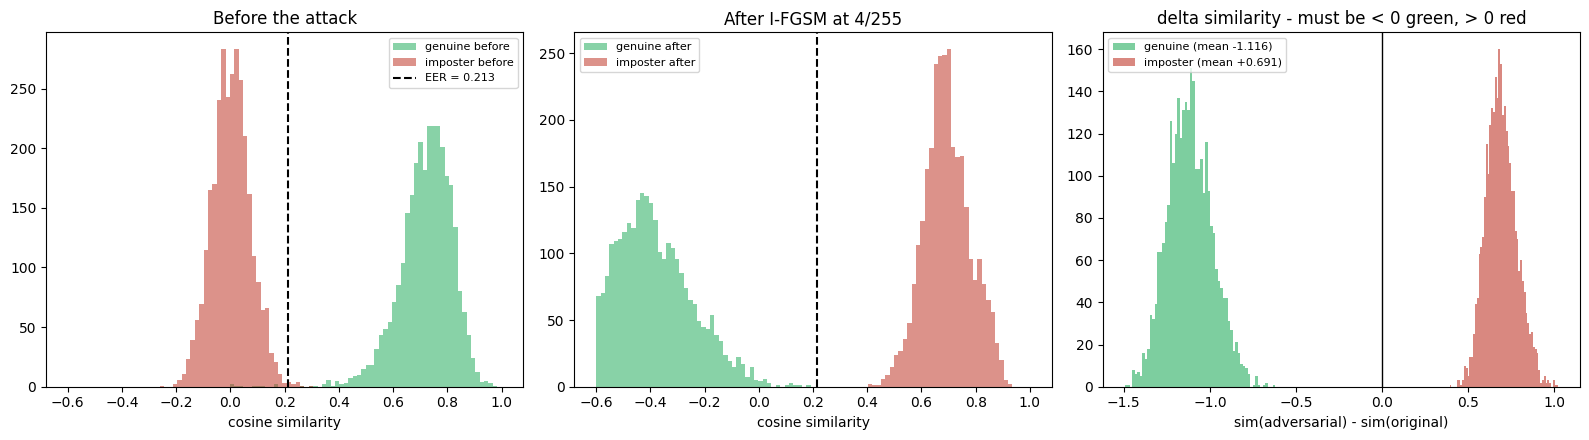

In [11]:
main = adf[(adf.attack == "ifgsm") & (adf.eps_255 == MAIN_EPS_255)]
g = main[main.genuine]; i = main[~main.genuine]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
bins = np.linspace(-0.6, 1.0, 100)

ax = axes[0]
ax.hist(g.sim_orig, bins=bins, alpha=0.55, color="#27ae60", label="genuine before")
ax.hist(i.sim_orig, bins=bins, alpha=0.55, color="#c0392b", label="imposter before")
ax.axvline(TAU_EER, color="k", ls="--", lw=1.5, label=f"EER = {TAU_EER:.3f}")
ax.set_title("Before the attack"); ax.set_xlabel("cosine similarity"); ax.legend(fontsize=8)

ax = axes[1]
ax.hist(g.sim_adv, bins=bins, alpha=0.55, color="#27ae60", label="genuine after")
ax.hist(i.sim_adv, bins=bins, alpha=0.55, color="#c0392b", label="imposter after")
ax.axvline(TAU_EER, color="k", ls="--", lw=1.5)
ax.set_title(f"After I-FGSM at {MAIN_EPS_255:g}/255")
ax.set_xlabel("cosine similarity"); ax.legend(fontsize=8)

ax = axes[2]
ax.hist(g.delta_sim, bins=60, alpha=0.6, color="#27ae60",
        label=f"genuine (mean {g.delta_sim.mean():+.3f})")
ax.hist(i.delta_sim, bins=60, alpha=0.6, color="#c0392b",
        label=f"imposter (mean {i.delta_sim.mean():+.3f})")
ax.axvline(0, color="k", lw=1)
ax.set_title("delta similarity - must be < 0 green, > 0 red")
ax.set_xlabel("sim(adversarial) - sim(original)"); ax.legend(fontsize=8)

plt.tight_layout(); save_fig("08_decision_attack_distributions.png"); plt.show()

saved /kaggle/working/08_epsilon_sweep.png


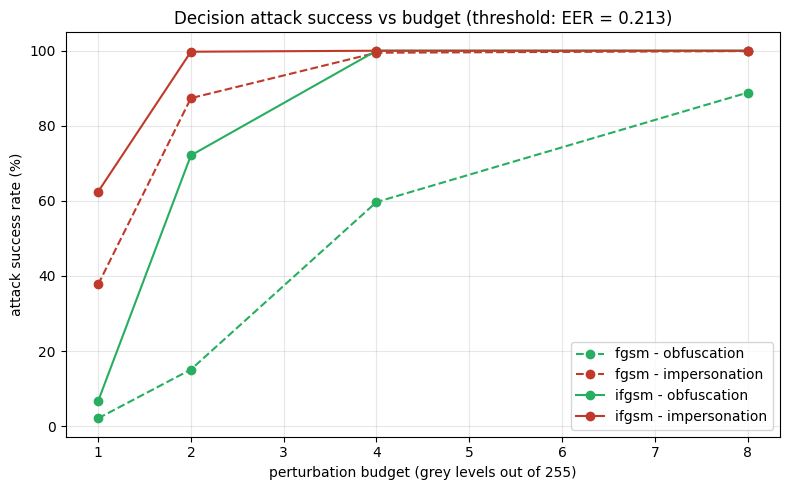

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for attack, ls in [("fgsm", "--"), ("ifgsm", "-")]:
    for direction, color in [("genuine", "#27ae60"), ("imposter", "#c0392b")]:
        sub = head_df[(head_df.attack == attack) & (head_df.direction == direction)]
        ax.plot(sub.eps_255, sub.success * 100, ls, marker="o", color=color,
                label=f"{attack} - {'obfuscation' if direction == 'genuine' else 'impersonation'}")
ax.set_xlabel("perturbation budget (grey levels out of 255)")
ax.set_ylabel("attack success rate (%)")
ax.set_title(f"Decision attack success vs budget (threshold: EER = {TAU_EER:.3f})")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); save_fig("08_epsilon_sweep.png"); plt.show()

## One pair from each direction, end to end

Each figure names the probe and the reference file, so which image was modified is never
in doubt. The perturbation panel is scaled so the full budget spans the colour range;
at these budgets the adversarial probe is visually indistinguishable from the original.

saved /kaggle/working/08_attack_pair0.png


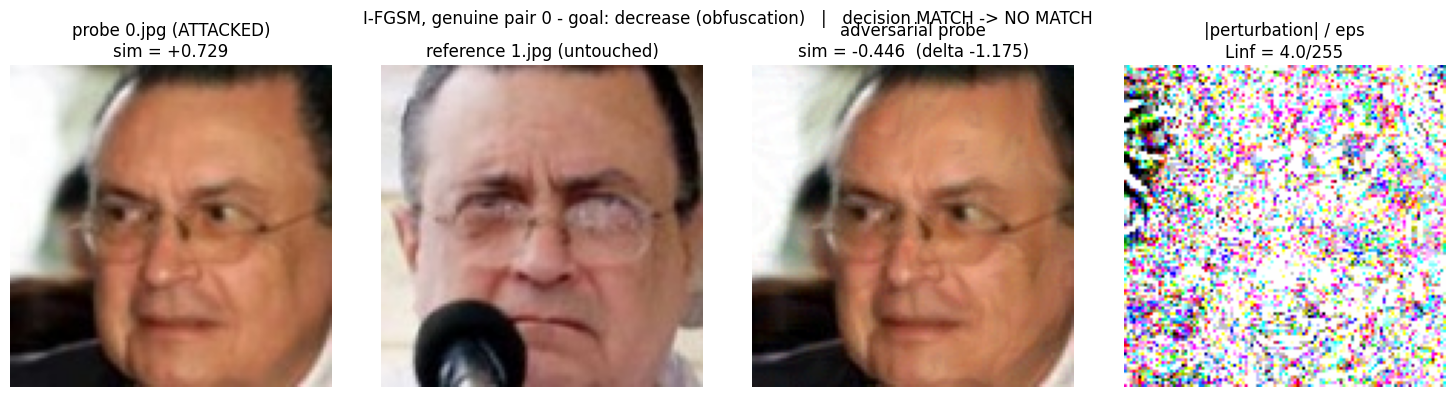

saved /kaggle/working/08_attack_pair300.png


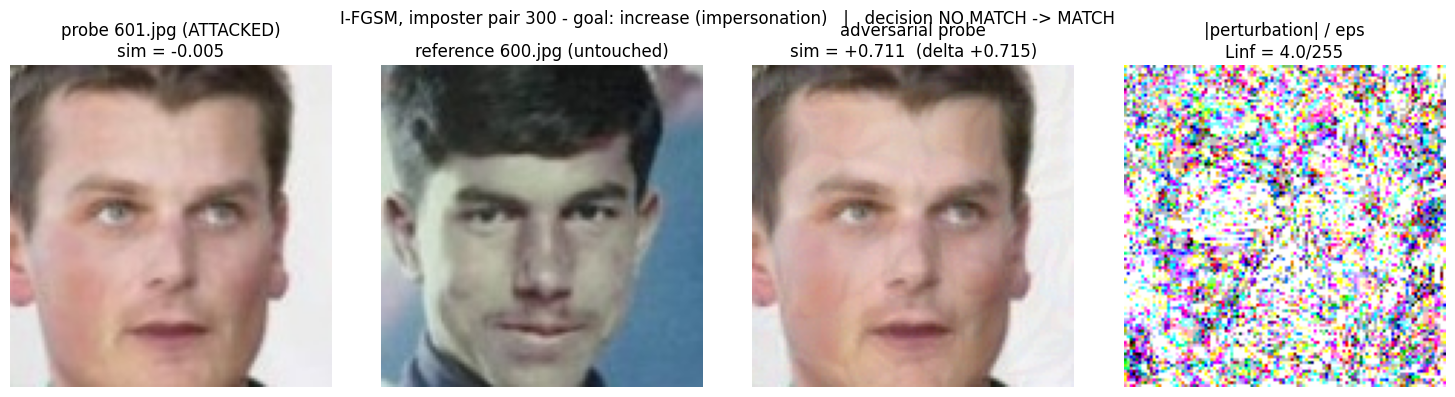

In [13]:
def show_attack(pair_idx, eps_255=None):
    eps_255 = MAIN_EPS_255 if eps_255 is None else eps_255
    eps = eps_to_norm(eps_255)
    probes, refs = load_pair_batch([pair_idx])
    ref_emb = embed_batch(refs)
    gmask = torch.tensor([bool(IS_GENUINE[pair_idx])], device=DEVICE)
    adv = decision_attack(probes, ref_emb, gmask, eps, ALPHA_FRAC * eps, STEPS_IFGSM)

    s0 = float((embed_batch(probes) * ref_emb).sum(1))
    s1 = float((embed_batch(adv) * ref_emb).sum(1))
    genuine = bool(IS_GENUINE[pair_idx])
    goal = "decrease (obfuscation)" if genuine else "increase (impersonation)"
    pr, rf = probe_reference(pair_idx)

    pert = ((adv - probes).abs() / eps).clamp(0, 1)
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(tensor_to_uint8(probes[0]))
    ax[0].set_title(f"probe {pr}.jpg (ATTACKED)\nsim = {s0:+.3f}")
    ax[1].imshow(tensor_to_uint8(refs[0]))
    ax[1].set_title(f"reference {rf}.jpg (untouched)")
    ax[2].imshow(tensor_to_uint8(adv[0]))
    ax[2].set_title(f"adversarial probe\nsim = {s1:+.3f}  (delta {s1 - s0:+.3f})")
    ax[3].imshow((pert[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8))
    ax[3].set_title(f"|perturbation| / eps\nLinf = {float((adv - probes).abs().max()) * 127.5:.1f}/255")
    for a in ax:
        a.axis("off")
    decided0 = "MATCH" if s0 >= TAU_EER else "NO MATCH"
    decided1 = "MATCH" if s1 >= TAU_EER else "NO MATCH"
    fig.suptitle(f"I-FGSM, {'genuine' if genuine else 'imposter'} pair {pair_idx} - "
                 f"goal: {goal}   |   decision {decided0} -> {decided1}", fontsize=12)
    plt.tight_layout()
    save_fig(f"08_attack_pair{pair_idx}.png")
    plt.show()


show_attack(VIZ_GENUINE_PAIR)
show_attack(VIZ_IMPOSTER_PAIR)

## Results and discussion

**Both directions behave correctly, in all sixteen configurations.** Genuine similarity
falls and imposter similarity rises, without exception - the summary cell asserts this and
would fail the notebook otherwise. At 4/255 with I-FGSM the mean change is **-1.116 for
obfuscation** and **+0.691 for impersonation**, taking genuine pairs from +0.720 to -0.396
and imposter pairs from +0.003 to +0.694. This closes the review point: the previously
reported behaviour - adversarial genuine pairs becoming *more* similar and imposter pairs
*less* - was a gradient-ascent bug in notebook 03 for the genuine half and, for the
imposter half, an experiment notebook 04 quietly stopped running.

**Only one image per pair is ever modified.** The probe/reference split is asserted pair by
pair, the probe is image 0 in 49.8% of pairs and image 1 in 50.2% (seeded coin flip), and
every figure and CSV row names both files. Probe and reference together cover all 12,000
images exactly once, so there is no configuration in which one image appears on both sides.

**Success rates.** At the EER threshold, I-FGSM at 4/255 reaches **100% in both
directions** with zero failures across 2,991 accepted genuine and 2,990 rejected imposter
pairs. Single-step FGSM is markedly weaker at the same budget (59.7% obfuscation, 99.5%
impersonation), which is the expected gap between a one-shot linearisation and 20
projected steps.

**The asymmetry, and why it runs the way it does.** At small budgets impersonation is
*easier*, not harder: at 1/255 I-FGSM succeeds on 62.4% of imposter pairs but only 6.7% of
genuine ones. That is the opposite of what the embedding geometry alone would suggest, and
the sweep separates the two competing effects:

* **Per unit of perturbation, obfuscation moves the score more** - 1.18x more at 1/255,
  rising to 1.73x at 8/255. This is the geometric effect: pushing an embedding *away* from
  a point is easier than steering it *toward* one, and the advantage grows with budget.
* **But obfuscation has 2.41x further to travel.** The EER threshold at 0.2134 sits close
  to the imposter mean (+0.003, a gap of 0.210) and far from the genuine mean (+0.720, a
  gap of 0.506).

The second effect dominates at low budgets, so impersonation wins on success rate even
though obfuscation wins on score displacement. Both saturate at 100% by 4/255. The
practical reading: success rates are as much a statement about **where the operating
threshold sits** as about the attack, which is precisely why notebook 06 had to fix the
threshold before any of this could be interpreted.

**Threshold sensitivity.** At 4/255 the attack succeeds at essentially 100% at every
operating point from FMR = 10^-1 to 10^-3, so nothing here depends on the choice of
threshold. The tiny dip in obfuscation at the loosest threshold (99.77% at FMR <= 0.1,
threshold 0.0942) is the expected direction: a lower threshold means a genuine score has
even further to fall.

**What this notebook is for.** Flipping a face verification decision with I-FGSM is well
established and is not a contribution. Its job is to prove the gradient pipeline is
correct end to end, at full scale and in both directions, so that when notebook 09 reports
"the decision was preserved while the explanation changed", the first half of that claim is
credible. A pipeline that cannot flip a decision on purpose cannot be trusted when it says
it did not flip one by accident.

**A note for notebook 09.** At 4/255 the similarity is extremely malleable - a *targeted*
attack moves it by more than 1.0, and every pair overshoots the threshold substantially.
Notebook 09 uses the same budget but must hold the score inside a +/-0.05 band, so its
hard projection will have real work to do. That is what the projection diagnostic in
notebook 09 reports, and why it is worth a short smoke run before the full one.

**Limitations.** These are white-box attacks with full gradient access, tested without
transferability, compression, or print-scan robustness, and constrained only by an
L-infinity ball rather than any perceptual model. All are standard for a warm-up and none
affect notebook 09, which operates under the same white-box assumption.
